## Avant de commencer l’analyse, nous importons les bibliothèques nécessaires. ###

Pandas permet de manipuler les données sous forme de DataFrame,
NumPy fournit des outils numériques, Matplotlib et Seaborn servent à créer des visualisations claires et lisibles.
La bibliothèque SQLite3 est utilisée pour établir une connexion avec la base de données SQLite fournie dans le projet. Elle permet d'exécuter des requêtes SQL et de récupérer les données de référence contenues dans les tables countries, channels et category_rules.

In [1]:

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns


## Ensuite, nous procèdons au chargements des fichiers demandés : 
### - le fichier CSV : sales_raw.csv
 ### - la base SQLite : bookworld_reference.db 
 ### - la première page du site à scraper : https://books.toscrape.com/ ;
 ### - l’API publique 


In [2]:
## Lecture du fichier CSV contenant les ventes
sales = pd.read_csv(r"C:\Users\ROGER\Downloads\sales_raw.csv")


print(sales.head())
print(sales.columns)
print(sales.info())

    order_id  order_date    book_id country_code channel_code  quantity  \
0  ORD000001  2025-06-13  BOOK00007           ES          APP         3   
1  ORD000002  2025-03-10  BOOK00020           FR          MKT         4   
2  ORD000004  2025-05-07  BOOK00015           IT          MKT         1   
3  ORD000005  2025-06-02  BOOK00011           ES          MKT         3   
4  ORD000006  2025-03-10  BOOK00008           IT          WEB         2   

   discount_rate customer_first_name customer_last_name  \
0           0.00                 Mia           Lefebvre   
1           0.15                Nina             Robert   
2           0.05                 Eva           Lefebvre   
3           0.00             Camille               Roux   
4           0.25               Clara            Mercier   

                                           book_name  
0  The Dirty Little Secrets of Getting Your Dream...  
1                            It's Only the Himalayas  
2                          Ri

In [3]:
# Les noms et prénoms n'étant pas nécessaires à l'analyse des ventes par pays, 
# Nous allons les supprimés afin de respecter le principe de minimisation des données du RGPD.

#Nettoyage RGPD 

sales = sales.drop(
    columns=[
        "customer_first_name",
        "customer_last_name"
    ]
)

print(sales.head())

    order_id  order_date    book_id country_code channel_code  quantity  \
0  ORD000001  2025-06-13  BOOK00007           ES          APP         3   
1  ORD000002  2025-03-10  BOOK00020           FR          MKT         4   
2  ORD000004  2025-05-07  BOOK00015           IT          MKT         1   
3  ORD000005  2025-06-02  BOOK00011           ES          MKT         3   
4  ORD000006  2025-03-10  BOOK00008           IT          WEB         2   

   discount_rate                                          book_name  
0           0.00  The Dirty Little Secrets of Getting Your Dream...  
1           0.15                            It's Only the Himalayas  
2           0.05                          Rip it Up and Start Again  
3           0.00     Starving Hearts (Triangular Trade Trilogy, #1)  
4           0.25  The Coming Woman: A Novel Based on the Life of...  


In [4]:
# On vérifie si il n'y a pas de doublons 
print(sales.duplicated().sum())

0


In [5]:
#On vérifie les valeurs manquantes 
print(sales.isnull().sum())

order_id         0
order_date       0
book_id          0
country_code     0
channel_code     0
quantity         0
discount_rate    0
book_name        0
dtype: int64


In [6]:
#Vérification des types de la structure 
print(sales.dtypes)

order_id             str
order_date           str
book_id              str
country_code         str
channel_code         str
quantity           int64
discount_rate    float64
book_name            str
dtype: object


In [7]:
#On convertit la date car elle est au format texte (string)
sales["order_date"] = pd.to_datetime(
    sales["order_date"]
)

In [8]:
#Puis on vérifie si le format est bien convertit
print(sales.dtypes)

order_id                    str
order_date       datetime64[us]
book_id                     str
country_code                str
channel_code                str
quantity                  int64
discount_rate           float64
book_name                   str
dtype: object


In [9]:
#Vérification des colonnes
print(sales.shape)
print(sales.columns)
print(sales.head())

(240, 8)
Index(['order_id', 'order_date', 'book_id', 'country_code', 'channel_code',
       'quantity', 'discount_rate', 'book_name'],
      dtype='str')
    order_id order_date    book_id country_code channel_code  quantity  \
0  ORD000001 2025-06-13  BOOK00007           ES          APP         3   
1  ORD000002 2025-03-10  BOOK00020           FR          MKT         4   
2  ORD000004 2025-05-07  BOOK00015           IT          MKT         1   
3  ORD000005 2025-06-02  BOOK00011           ES          MKT         3   
4  ORD000006 2025-03-10  BOOK00008           IT          WEB         2   

   discount_rate                                          book_name  
0           0.00  The Dirty Little Secrets of Getting Your Dream...  
1           0.15                            It's Only the Himalayas  
2           0.05                          Rip it Up and Start Again  
3           0.00     Starving Hearts (Triangular Trade Trilogy, #1)  
4           0.25  The Coming Woman: A Novel Based o

In [10]:
#Ce qui nous permet de voir si ce fichier contient toutes les données nécessaires pour la suite de l'analyse.
sales.describe(include="all")

,order_id,order_date,book_id,country_code,channel_code,quantity,discount_rate,book_name
count,240,240,240,240,240,240.000000,240.000000,240
unique,240,NaN,20,8,3,NaN,NaN,20
top,ORD000001,NaN,BOOK00007,FR,WEB,NaN,NaN,The Dirty Little Secrets of Getting Your Dream...
freq,1,NaN,18,56,146,NaN,NaN,18
mean,NaN,2025-04-08 11:24:00,NaN,NaN,NaN,2.512500,0.110208,NaN
min,NaN,2025-01-03 00:00:00,NaN,NaN,NaN,1.000000,0.000000,NaN
25%,NaN,2025-03-02 00:00:00,NaN,NaN,NaN,1.000000,0.000000,NaN
50%,NaN,2025-04-09 12:00:00,NaN,NaN,NaN,2.000000,0.100000,NaN
75%,NaN,2025-05-22 06:00:00,NaN,NaN,NaN,3.000000,0.200000,NaN
max,NaN,2025-06-29 00:00:00,NaN,NaN,NaN,8.000000,0.400000,NaN


# Interprétation des résultats
Les valeurs NaN visibles dans le tableau produit par describe(include="all") ne correspondent pas à des données manquantes.

Elles apparaissent car certaines statistiques ne sont pas applicables à certains types de variables. Par exemple, il n'est pas possible de calculer une moyenne (mean) sur une variable textuelle comme order_id, ni d'afficher un nombre de modalités uniques (unique) pour certaines variables numériques.

La vérification des données manquantes a été réalisée précédemment à l'aide de :

sales.isnull().sum()


In [11]:
#Pour la base SQLite
# Bookworld_reference.db, je vais utiliser sqlite3 pour me connecter à la base de données et lire les tables.
import sqlite3

conn = sqlite3.connect(
    r"C:\Users\ROGER\Downloads\bookworld_reference.db"
)

In [12]:
# Nous affichons la liste des tables présentes dans la base.

# Cela permet d'identifier les données disponibles avant de commencer les analyses.

tables = pd.read_sql("""
SELECT name
FROM sqlite_master
WHERE type='table';
""", conn)

print(tables)

             name
0        channels
1       countries
2  category_rules


In [13]:
# Ici, on récupère les premières lignes de la table channels.

# Cette table contient les informations sur les canaux de vente utilisés par BookWorld (site web, application mobile, marketplace).

# Cela nous permet de comprendre quelles données pourront être utilisées pour enrichir notre analyse.

pd.read_sql(
    "SELECT * FROM channels LIMIT 5;",
    conn
)

,channel_code,channel_name,acquisition_cost_gbp,channel_group,is_active
0,WEB,Website,2.5,Owned,1
1,APP,Mobile App,1.8,Owned,1
2,MKT,Marketplace,6.2,Partner,1
3,AFF,Affiliate Network,4.1,Partner,0


In [14]:
# Ici, on récupère les informations sur les pays.

# Cette table contient le code du pays, son nom, sa devise et son taux de TVA.

# Ces données pourront être utilisées pour enrichir le jeu de données final.

pd.read_sql(
    "SELECT * FROM countries LIMIT 5;",
    conn
)

,country_code,country_name,currency_code,vat_rate,region,is_active
0,FR,France,EUR,20.0,Europe,1
1,BE,Belgium,EUR,21.0,Europe,1
2,DE,Germany,EUR,19.0,Europe,1
3,ES,Spain,EUR,21.0,Europe,1
4,IT,Italy,EUR,22.0,Europe,1


In [15]:
# Ici, on consulte les règles associées aux catégories de livres.

# Cette table indique notamment le taux de marge et le canal de vente recommandé.

pd.read_sql(
    "SELECT * FROM category_rules LIMIT 5;",
    conn
)

,category_name,margin_rate,strategic_flag,default_channel_code,is_active
0,Travel,0.32,1,WEB,1
1,Mystery,0.28,1,APP,1
2,Historical Fiction,0.30,0,WEB,1
3,Classics,0.26,0,WEB,1
4,Romance,0.34,1,APP,1


Puis on vérifie la structure 

In [16]:
pd.read_sql(
    "PRAGMA table_info(channels);",
    conn
)

,cid,name,type,notnull,dflt_value,pk
0,0,channel_code,TEXT,0,None,1
1,1,channel_name,TEXT,1,None,0
2,2,acquisition_cost_gbp,REAL,1,None,0
3,3,channel_group,TEXT,1,None,0
4,4,is_active,INTEGER,1,None,0


In [17]:
pd.read_sql(
    "PRAGMA table_info(countries);",
    conn
)

,cid,name,type,notnull,dflt_value,pk
0,0,country_code,TEXT,0,None,1
1,1,country_name,TEXT,1,None,0
2,2,currency_code,TEXT,1,None,0
3,3,vat_rate,REAL,1,None,0
4,4,region,TEXT,1,None,0
5,5,is_active,INTEGER,1,None,0


In [18]:
pd.read_sql(
    "PRAGMA table_info(category_rules);",
    conn
)

,cid,name,type,notnull,dflt_value,pk
0,0,category_name,TEXT,0,None,1
1,1,margin_rate,REAL,1,None,0
2,2,strategic_flag,INTEGER,1,None,0
3,3,default_channel_code,TEXT,1,None,0
4,4,is_active,INTEGER,1,None,0


In [19]:
# Cette table contient les informations relatives aux pays.

# On retrouve notamment :
# - le code du pays
# - son nom
# - sa devise
# - son taux de TVA
# - sa région

pd.read_sql(
    "SELECT * FROM countries LIMIT 5;",
    conn
)

,country_code,country_name,currency_code,vat_rate,region,is_active
0,FR,France,EUR,20.0,Europe,1
1,BE,Belgium,EUR,21.0,Europe,1
2,DE,Germany,EUR,19.0,Europe,1
3,ES,Spain,EUR,21.0,Europe,1
4,IT,Italy,EUR,22.0,Europe,1


In [20]:
# Cette table contient les différents canaux de vente utilisés par l'entreprise.

# Elle fournit également le coût d'acquisition
# ainsi que le type de canal.

channels = pd.read_sql(
    "SELECT * FROM channels LIMIT 5;",
    conn
)

print(channels)

  channel_code       channel_name  acquisition_cost_gbp channel_group  \
0          WEB            Website                   2.5         Owned   
1          APP         Mobile App                   1.8         Owned   
2          MKT        Marketplace                   6.2       Partner   
3          AFF  Affiliate Network                   4.1       Partner   

   is_active  
0          1  
1          1  
2          1  
3          0  


In [21]:
# La table category_rules contient différentes règles métier.

# On y retrouve notamment :
# - la catégorie
# - le taux de marge
# - les catégories stratégiques
# - le canal de vente recommandé

category_rules = pd.read_sql(
    "SELECT * FROM category_rules LIMIT 5;",
    conn
)

print(category_rules)

        category_name  margin_rate  strategic_flag default_channel_code  \
0              Travel         0.32               1                  WEB   
1             Mystery         0.28               1                  APP   
2  Historical Fiction         0.30               0                  WEB   
3            Classics         0.26               0                  WEB   
4             Romance         0.34               1                  APP   

   is_active  
0          1  
1          1  
2          1  
3          1  
4          1  


In [22]:
# Cette table contient les informations relatives aux pays.

# On retrouve notamment :
# - le code du pays
# - son nom
# - sa devise
# - son taux de TVA
# - sa région

countries = pd.read_sql(
    "SELECT * FROM countries;",
    conn
)

print(countries.head())


  country_code country_name currency_code  vat_rate  region  is_active
0           FR       France           EUR      20.0  Europe          1
1           BE      Belgium           EUR      21.0  Europe          1
2           DE      Germany           EUR      19.0  Europe          1
3           ES        Spain           EUR      21.0  Europe          1
4           IT        Italy           EUR      22.0  Europe          1


In [23]:
sales_by_country = (
    sales.groupby("country_code")
    .agg(
        total_orders=("order_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

In [24]:
# Enrichissement des données de ventes

# Ici, nous ajoutons le nom complet du pays
# aux résultats d'agrégation.

# La jointure est réalisée à partir du code pays
# présent dans le fichier de ventes et dans la table countries.
# Lors du contrôle de cohérence,
# le pays NL n'a pas trouvé de correspondance
# dans la table countries.

sales_by_country = sales_by_country.merge(
    countries[
        ["country_code", "country_name"]
    ],
    on="country_code",
    how="left"
)

print(sales_by_country)

  country_code  total_orders  total_quantity country_name
0           BE            30              81      Belgium
1           DE            40             110      Germany
2           ES            28              64        Spain
3           FR            56             130       France
4           IE            19              46      Ireland
5           IT            28              57        Italy
6           NL            19              55          NaN
7           PT            20              60     Portugal


Lors de l'enrichissement des données, le pays NL n'a pas trouvé de correspondance dans la table de référence countries. Cette observation met en évidence l'importance du contrôle qualité des référentiels.

### On récupère les livres de la première page de : "https://books.toscrape.com/"

In [25]:
# Requests permet d'envoyer une requête HTTP vers une page web et de récupérer son contenu HTML.
# BeautifulSoup (bibliothèque bs4) permet d'analyser le code HTML récupéré et
# d'extraire les informations souhaitées, comme les titres de livres, les prix ou d'autres éléments présents sur la page

## Dans ce projet, requests est utilisé pour télécharger le contenu de la page Books To Scrape.
## BeautifulSoup est utilisé pour parcourir le code HTML de cette page et récupérer les informations sur les livres (titres, prix, etc.).
import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"

response = requests.get(url)

print(response.status_code)


200


In [26]:
#Affichage des titres des 5 premiers livres

soup = BeautifulSoup(response.text, "html.parser")

titres = soup.find_all("h3")

for titre in titres[:5]:
    print(titre.text)

A Light in the ...
Tipping the Velvet
Soumission
Sharp Objects
Sapiens: A Brief History ...


In [27]:
#Affichage du nombre de livres sur la page 
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

livres = soup.find_all("article", class_="product_pod")

print("Nombre de livres :", len(livres))

Nombre de livres : 20


In [28]:
for livre in livres[:5]:
    titre = livre.h3.a["title"]

    prix = livre.find("p", class_="price_color").text

    print(titre)
    print(prix)
    print("-" * 30)

A Light in the Attic
Â£51.77
------------------------------
Tipping the Velvet
Â£53.74
------------------------------
Soumission
Â£50.10
------------------------------
Sharp Objects
Â£47.82
------------------------------
Sapiens: A Brief History of Humankind
Â£54.23
------------------------------


#### On va créer un DataFrame avec les livres scrapés 

In [29]:
titles = []
prices = []

for livre in livres:
    titles.append(livre.h3.a["title"])

    price = (
        livre.find("p", class_="price_color")
        .text
        .replace("Â£", "")
    )

    prices.append(price)

books_df = pd.DataFrame({
    "book_name": titles,
    "price_gbp": prices
})

print(books_df.head())

                               book_name price_gbp
0                   A Light in the Attic     51.77
1                     Tipping the Velvet     53.74
2                             Soumission     50.10
3                          Sharp Objects     47.82
4  Sapiens: A Brief History of Humankind     54.23


# Récupération du taux de change
L'API Frankfurter est utilisée pour récupérer le taux de conversion de la livre sterling (GBP) vers l'euro (EUR).

Cette information pourra être utilisée pour convertir les prix récupérés lors du scraping.

In [30]:
import requests

try:

    url = "https://api.frankfurter.app/latest?from=GBP&to=EUR"

    response = requests.get(url)

    response.raise_for_status()

    data = response.json()

    print(data)

except Exception as e:

    print("Erreur :", e)

{'amount': 1.0, 'base': 'GBP', 'date': '2026-11-24', 'rates': {'EUR': 1.1947}}


In [31]:
# On va calculer quelques indicateurs : 
print(
    "Nombre de commandes :",
    sales["order_id"].nunique()
)

print(
    "Quantité totale vendue :",
    sales["quantity"].sum()
)

print(
    sales.groupby("country_code")["quantity"].sum()
)

Nombre de commandes : 240
Quantité totale vendue : 603
country_code
BE     81
DE    110
ES     64
FR    130
IE     46
IT     57
NL     55
PT     60
Name: quantity, dtype: int64


In [32]:
#Calcul de la quantité totale vendue
sales.shape
sales["country_code"].value_counts()
sales["quantity"].sum()

np.int64(603)

Après nettoyage des données, le volume total vendu dans le jeu de données représente 603 unités.

In [33]:
#On convertit d'abord le prix en nombre 
books_df["price_gbp"] = books_df["price_gbp"].astype(float)

In [34]:
#Puis on fait la jointure entre les deux 
sales_enriched = sales.merge(
    books_df,
    on="book_name",
    how="left"
)

In [35]:
#On calcul le chiffre d'affaire 
sales_enriched["revenue_gbp"] = (
    sales_enriched["quantity"]
    * sales_enriched["price_gbp"]
)

In [36]:
#On récupère le taux GBP = EUR 
exchange_rate = data["rates"]["EUR"]

In [37]:
sales_enriched["revenue_eur"] = (
    sales_enriched["revenue_gbp"]
    * exchange_rate
)

In [38]:
#Agrégation des ventes par pays 
sales_by_country = (
    sales_enriched
    .groupby("country_code")
    .agg(
        total_orders=("order_id", "nunique"),
        total_quantity=("quantity", "sum"),
        total_revenue_gbp=("revenue_gbp", "sum"),
        total_revenue_eur=("revenue_eur", "sum")
    )
    .reset_index()
)

In [39]:
sales_by_country = sales_by_country.merge(
    countries[
        ["country_code", "country_name"]
    ],
    on="country_code",
    how="left"
)

In [40]:
#On calcule le nombre de commandes:
print(sales["order_id"].nunique())

240


In [41]:
#On calcule le nombre de commandes par canal: 
print(sales["channel_code"].value_counts())

channel_code
WEB    146
APP     54
MKT     40
Name: count, dtype: int64


In [42]:
final_conn = sqlite3.connect(
    "bookworld_final.db"
)

sales_by_country.to_sql(
    "sales_by_country",
    final_conn,
    if_exists="replace",
    index=False
)

final_conn.close()

In [43]:
print(
    sales_enriched[
        ["book_name",
         "quantity",
         "price_gbp",
         "revenue_eur",
         "revenue_gbp"]
    ].head()
)

                                           book_name  quantity  price_gbp  \
0  The Dirty Little Secrets of Getting Your Dream...         3      33.34   
1                            It's Only the Himalayas         4      45.17   
2                          Rip it Up and Start Again         1      35.02   
3     Starving Hearts (Triangular Trade Trilogy, #1)         3      13.99   
4  The Coming Woman: A Novel Based on the Life of...         2      17.93   

   revenue_eur  revenue_gbp  
0   119.493894       100.02  
1   215.858396       180.68  
2    41.838394        35.02  
3    50.141559        41.97  
4    42.841942        35.86  


In [44]:
print(sales_by_country.columns)

Index(['country_code', 'total_orders', 'total_quantity', 'total_revenue_gbp',
       'total_revenue_eur', 'country_name'],
      dtype='str')


In [45]:
print(sales_by_country.head())

  country_code  total_orders  total_quantity  total_revenue_gbp  \
0           BE            30              81            3154.70   
1           DE            40             110            4377.65   
2           ES            28              64            2086.54   
3           FR            56             130            4484.11   
4           IE            19              46            2068.22   

   total_revenue_eur country_name  
0        3768.920090      Belgium  
1        5229.978455      Germany  
2        2492.789338        Spain  
3        5357.166217       France  
4        2470.902434      Ireland  


# Synthèse des résultats
L'analyse des données permet d'obtenir plusieurs indicateurs métier :

240 commandes ont été enregistrées.
603 livres ont été vendus.
Les ventes concernent 8 pays différents.
Trois canaux de vente sont utilisés : WEB, APP et MKT.
Le canal WEB est le plus utilisé avec 146 commandes.

La France est le pays présentant le volume de ventes le plus élevé avec 130 livres vendus.

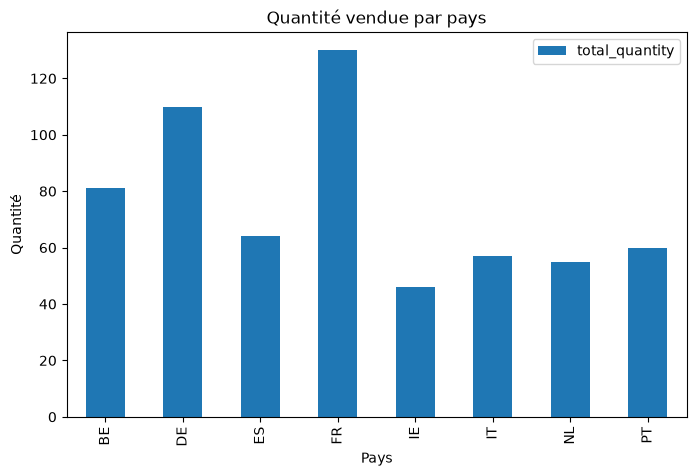

In [46]:
#Pour un résultat plus visuel, on peut représenter les ventes par pays sous forme de graphique à barres.

sales_by_country.plot(
    x="country_code",
    y="total_quantity",
    kind="bar",
    figsize=(8,5)
)

plt.title("Quantité vendue par pays")
plt.xlabel("Pays")
plt.ylabel("Quantité")
plt.show()

### Exposition des données via API REST
Une API REST a été développée dans le fichier api.py afin d'exposer les indicateurs métier du projet.

Les données du catalogue ont été récupérées via le scraping de la première page du site BooksToScrape afin de démontrer la collecte de données depuis une source web externe.

Cette cellule représente le point d'entrée du script conformément aux attendus du projet.

In [47]:
def main():

    print("Projet BookWorld exécuté")

if __name__ == "__main__":
    main()

Projet BookWorld exécuté
